# EDA: режимы электрической сети (35 узлов, 80 линий)

**Файлы:** `train_nodes_34.csv` (узлы), `train_lines_34.csv` (линии). Связь между ними: `ID_опыта`.

**План:**
0. Загрузка и общий обзор
1. Проверка гипотезы: если `regime_valid=0` хотя бы в одном узле опыта, то во всех узлах опыта = 0
2. Связь `Q_н` и `P_н` (`Q = k·P`?)
3. `P_г` в узлах 29 и 33 (и вообще по всем узлам, баланс, балансирующий узел)
4. Разделение на valid=1 / valid=0, сравнение распределений
5. Линии: что постоянно, что меняется, связь `I_max`, `I_доп`, `I_zarg`
6. Корреляции: входы (нагрузка/генерация/параметры линий) → выходы (V, Delta, I_max, I_zarg)
7. Что влияет на сходимость (классификация)
8. Итоги

In [4]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

NODES_PATH = "train_nodes_34_100000.csv"
LINES_PATH = "train_lines_34_100000.csv"

## 0. Загрузка и общий обзор

In [5]:
def load(path):
    df = pd.read_csv(path)
    if df.shape[1] == 1:               # на случай разделителя ';'
        df = pd.read_csv(path, sep=";")
    df.columns = df.columns.str.strip()
    return df

nodes_raw, lines_raw = load(NODES_PATH), load(LINES_PATH)
print(nodes_raw.columns.tolist())
print(lines_raw.columns.tolist())

# ASCII-имена, чтобы удобнее писать код (порядок колонок как в ТЗ / на скриншотах)
nodes = nodes_raw.copy()
lines = lines_raw.copy()
nodes.columns = ["id", "node", "U_nom", "P_load", "Q_load", "P_gen", "V", "Delta", "valid"]
lines.columns = ["id", "line", "n_s", "n_e", "type", "R", "X", "B", "Kt", "I_max", "I_dop", "I_zarg"]

# Эталонный (опорный) узел: в линиях закодирован как 999, в таблице узлов это узел -1
lines[["n_s", "n_e"]] = lines[["n_s", "n_e"]].replace(999, -1)

# относительное напряжение (о.е.) - удобно сравнивать узлы 110/220/500 кВ
nodes["V_pu"] = nodes["V"] / nodes["U_nom"]

['ID_опыта', 'Номер', 'U_ном', 'P_н', 'Q_н', 'P_г', 'V', 'Delta', 'regime_valid']
['ID_опыта', 'Номер', 'N_s', 'N_e', 'type', 'R', 'X', 'B', 'Kt', 'I_max', 'I_доп', 'I_zarg']


In [6]:
for name, df in [("nodes", nodes), ("lines", lines)]:
    print("=" * 30, name, df.shape)
    display(df.head(8))
    display(df.describe().T)
    na = df.isna().sum()
    print("NaN по колонкам:\n", na[na > 0] if (na > 0).any() else "пропусков нет")

============================== nodes (3500000, 10)


,id,node,U_nom,P_load,Q_load,P_gen,V,Delta,valid,V_pu
0,1,1,500.0000,0.0000,0.0000,0.0000,510.0000,-17.3850,1,1.0200
1,1,2,500.0000,0.0000,0.0000,0.0000,510.0000,-10.6690,1,1.0200
2,1,3,500.0000,0.0000,0.0000,0.0000,506.7090,-10.5300,1,1.0134
3,1,4,500.0000,0.0000,0.0000,0.0000,510.0000,-3.1130,1,1.0200
4,1,5,500.0000,0.0000,0.0000,0.0000,467.4960,-21.3150,1,0.9350
5,1,6,500.0000,0.0000,0.0000,0.0000,466.8900,-21.3000,1,0.9338
6,1,7,500.0000,0.0000,0.0000,0.0000,510.0000,-7.3770,1,1.0200
7,1,8,220.0000,75.6720,37.8360,0.0000,232.8550,-11.3590,1,1.0584


,count,mean,std,min,25%,50%,75%,max
id,"3,500,000.0000","81,697.7375","48,006.9832",1.0000,"40,514.7500","80,776.5000","121,315.2500","170,392.0000"
node,"3,500,000.0000",45.5429,163.8022,1.0000,9.0000,18.0000,27.0000,999.0000
U_nom,"3,500,000.0000",236.8571,151.0681,110.0000,110.0000,220.0000,220.0000,500.0000
P_load,"3,500,000.0000",109.9706,136.5321,0.0000,0.0000,21.7650,209.2960,660.7820
Q_load,"3,500,000.0000",54.8529,70.6881,0.0000,0.0000,10.8830,104.2810,325.1540
P_gen,"3,500,000.0000",45.0647,271.8803,0.0000,0.0000,0.0000,0.0000,"2,689.0170"
V,"3,500,000.0000",111.7852,157.4409,0.0000,0.0000,68.3855,185.9230,510.0000
Delta,"3,500,000.0000",-12.5720,15.2922,-58.2530,-29.2910,0.0000,0.0000,0.0000
valid,"3,500,000.0000",0.5009,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000
V_pu,"3,500,000.0000",0.4551,0.4592,0.0000,0.0000,0.6156,0.9053,1.0624


NaN по колонкам:
 пропусков нет
============================== lines (8000000, 12)


,id,line,n_s,n_e,type,R,X,B,Kt,I_max,I_dop,I_zarg
0,1,1,-1,3,0,2.9600,45.6000,-546.8000,0.0000,"1,177.2000","3,003.1000",39.2000
1,1,2,-1,4,0,1.1800,18.2400,-218.7000,0.0000,876.9000,"3,003.1000",29.2000
2,1,3,15,16,0,1.1000,6.3000,-40.5000,0.0000,632.7000,824.9000,76.7000
3,1,4,16,22,1,0.5700,29.0900,18.8000,0.5050,382.0000,478.7000,79.8000
4,1,5,10,15,0,1.4600,8.4000,-54.0000,0.0000,557.7000,825.0000,67.6000
5,1,6,15,23,1,0.4400,23.2700,23.5000,0.5050,385.2000,600.0000,64.2000
6,1,7,10,17,0,1.1000,6.3000,-40.5000,0.0000,609.9000,825.3000,73.9000
7,1,8,10,11,0,1.9200,8.5800,-52.9000,0.0000,101.4000,709.1000,14.3000


,count,mean,std,min,25%,50%,75%,max
id,"8,000,000.0000","81,697.7375","48,006.9793",1.0000,"40,514.7500","80,776.5000","121,315.2500","170,392.0000"
line,"8,000,000.0000",40.5000,23.0922,1.0000,20.7500,40.5000,60.2500,80.0000
n_s,"8,000,000.0000",13.8875,8.7164,-1.0000,8.7500,13.0000,23.0000,30.0000
n_e,"8,000,000.0000",19.8875,9.4485,2.0000,11.7500,21.0000,28.0000,34.0000
type,"8,000,000.0000",0.3000,0.4583,0.0000,0.0000,0.0000,1.0000,1.0000
R,"8,000,000.0000",3.6528,4.8235,0.2200,0.5475,1.1000,4.1500,20.4000
X,"8,000,000.0000",30.6349,29.6345,2.1500,8.4000,23.2700,44.0250,182.4000
B,"8,000,000.0000",-189.2838,380.4830,"-2,187.0000",-196.6750,-40.8500,11.1000,23.5000
Kt,"8,000,000.0000",0.1470,0.2248,0.0000,0.0000,0.0000,0.4600,0.5050
I_max,"4,006,800.0000",378.6474,283.0962,6.7000,152.9000,322.9000,502.4000,"1,766.0000"


NaN по колонкам:
 I_max     3993200
I_dop     3993200
I_zarg    3993200
dtype: int64


In [7]:
print("Опытов в nodes:", nodes.id.nunique(), "| в lines:", lines.id.nunique())
print("Множества ID совпадают:", set(nodes.id) == set(lines.id))
print("\nУзлов на опыт:");  print(nodes.groupby("id").size().value_counts())
print("\nЛиний на опыт:");  print(lines.groupby("id").size().value_counts())
print("\nДубликаты (id,node):", nodes.duplicated(["id", "node"]).sum(),
      "| (id,line):", lines.duplicated(["id", "line"]).sum())
print("\nУзлы:", sorted(nodes.node.unique()))
print("Номинальные напряжения:", nodes.groupby("U_nom").node.nunique().to_dict(), "(узлов на класс)")
REF = -1  # эталонный (опорный) балансирующий узел (999 в линиях = -1 в узлах)
print("Концы линий вне таблицы узлов:", sorted((set(lines.n_s) | set(lines.n_e)) - set(nodes.node)) or "нет")
print("Линий, подключённых к эталонному узлу (-1):", lines[(lines.n_s == REF) | (lines.n_e == REF)].line.nunique())

Опытов в nodes: 100000 | в lines: 100000
Множества ID совпадают: True

Узлов на опыт:
35    100000
Name: count, dtype: int64

Линий на опыт:
80    100000
Name: count, dtype: int64

Дубликаты (id,node): 0 | (id,line): 0

Узлы: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(999)]
Номинальные напряжения: {110.0: 15, 220.0: 12, 500.0: 8} (узлов на класс)
Концы линий вне таблицы узлов: [-1]
Линий, подключённых к эталонному узлу (-1): 5


## 1. Гипотеза: флаг `regime_valid` одинаков во всех узлах опыта

Если в опыте хоть в одном узле флаг = 0, то и во всех остальных = 0.

In [8]:
g = nodes.groupby("id")["valid"]
exp = pd.DataFrame({"vmin": g.min(), "vmax": g.max(), "share_valid": g.mean(), "n_nodes": g.size()})
mixed = exp[exp.vmin != exp.vmax]

print(f"Опытов всего: {len(exp)}")
print(f"Опытов со СМЕШАННЫМ флагом (и 0 и 1 внутри опыта): {len(mixed)}")
if len(mixed):
    print("Гипотеза НЕ подтверждена, примеры:")
    display(mixed.head(10))
    display(mixed.share_valid.describe())
else:
    print("Гипотеза ПОДТВЕРЖДЕНА: флаг един для всего опыта.")

# флаг уровня опыта (если смешанный - считаем опыт невалидным, если есть хоть один 0)
exp_valid = exp["vmin"].rename("valid_exp")
print("\nДоля валидных опытов:")
print(exp_valid.value_counts(normalize=True).rename({0: "invalid (0)", 1: "valid (1)"}))
nodes = nodes.merge(exp_valid, left_on="id", right_index=True)
lines = lines.merge(exp_valid, left_on="id", right_index=True)

Опытов всего: 100000
Опытов со СМЕШАННЫМ флагом (и 0 и 1 внутри опыта): 0
Гипотеза ПОДТВЕРЖДЕНА: флаг един для всего опыта.

Доля валидных опытов:
valid_exp
valid (1)     0.5009
invalid (0)   0.4991
Name: proportion, dtype: float64


## 2. `Q_н` vs `P_н`: есть ли постоянный коэффициент (tgφ)?

In [9]:
print("P_load<0:", (nodes.P_load < 0).sum(), "| Q_load<0:", (nodes.Q_load < 0).sum())
print("P!=0 & Q==0:", ((nodes.P_load != 0) & (nodes.Q_load == 0)).sum())
print("P==0 & Q!=0:", ((nodes.P_load == 0) & (nodes.Q_load != 0)).sum())
print("Узлов-строк с ненулевой нагрузкой:", (nodes.P_load != 0).mean().round(3))

def tg_stats(d):
    m = d.P_load != 0
    t = d.Q_load[m] / d.P_load[m]
    return pd.Series({
        "rows": len(d),
        "P_nonzero_share": m.mean(),
        "Q_nonzero_share": (d.Q_load != 0).mean(),
        "tg_mean": t.mean(), "tg_std": t.std(), "tg_min": t.min(), "tg_max": t.max(),
        "tg_unique(round4)": t.round(4).nunique() if len(t) else 0,
        "corr(P,Q)": d[["P_load", "Q_load"]].corr().iloc[0, 1] if m.any() else np.nan,
    })

per_node_tg = nodes.groupby("node").apply(tg_stats)
display(per_node_tg)

P_load<0: 0 | Q_load<0: 0
P!=0 & Q==0: 0
P==0 & Q!=0: 0
Узлов-строк с ненулевой нагрузкой: 0.571


,rows,P_nonzero_share,Q_nonzero_share,tg_mean,tg_std,tg_min,tg_max,tg_unique(round4),"corr(P,Q)"
node,,,,,,,,,
1,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
2,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
3,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
4,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
5,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
6,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
7,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN
8,"100,000.0000",1.0000,1.0000,0.5000,0.0000,0.5000,0.5000,1.0000,1.0000
9,"100,000.0000",0.0000,0.0000,NaN,NaN,NaN,NaN,0.0000,NaN


Глобально tg = Q/P:


count   2,000,000.0000
mean            0.4949
std             0.1314
min             0.3000
25%             0.5000
50%             0.5000
75%             0.5000
max             1.0000
Name: tg, dtype: float64


По классам напряжения:


,count,mean,std,min,25%,50%,75%,max
U_nom,,,,,,,,
110.0000,"1,500,000.0000",0.4843,0.0402,0.3750,0.5000,0.5000,0.5000,0.5000
220.0000,"500,000.0000",0.5267,0.2507,0.3000,0.3333,0.5000,0.5000,1.0000


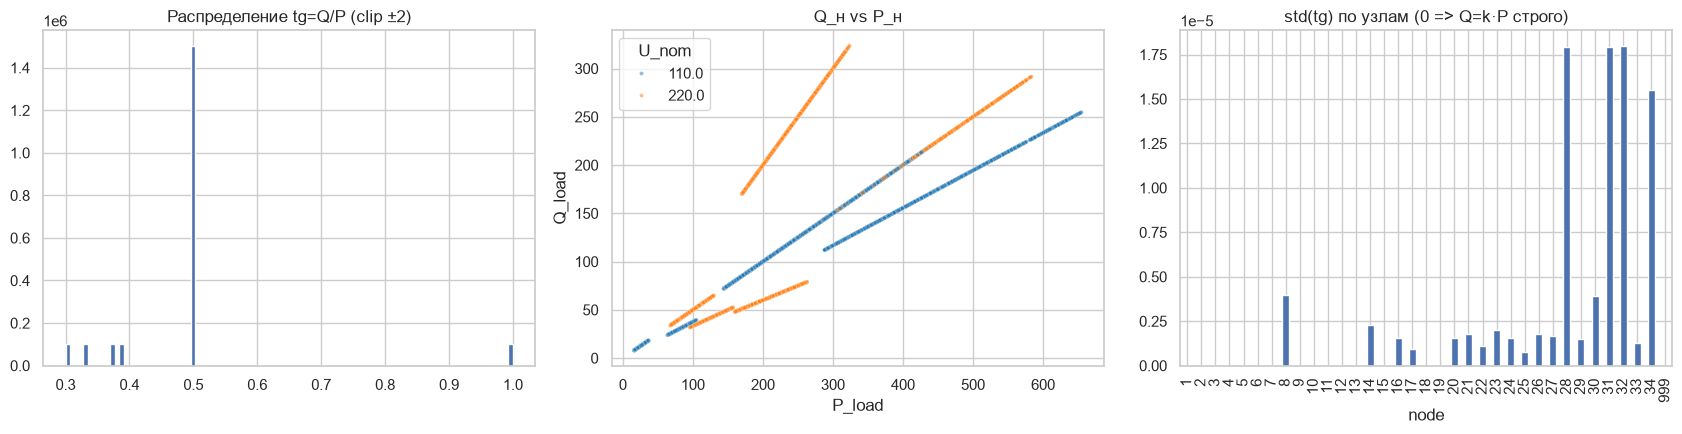

Узлов, где tg фактически константа (std<1e-3): 20 из 20


In [10]:
nz = nodes[nodes.P_load != 0].copy()
nz["tg"] = nz.Q_load / nz.P_load

print("Глобально tg = Q/P:")
display(nz.tg.describe())
print("\nПо классам напряжения:")
display(nz.groupby("U_nom").tg.describe())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
nz.tg.clip(-2, 2).hist(bins=100, ax=ax[0]); ax[0].set_title("Распределение tg=Q/P (clip ±2)")
sns.scatterplot(data=nz.sample(min(20000, len(nz)), random_state=0), x="P_load", y="Q_load",
                hue="U_nom", s=8, alpha=.5, ax=ax[1], palette="tab10"); ax[1].set_title("Q_н vs P_н")
per_node_tg["tg_std"].plot.bar(ax=ax[2]); ax[2].set_title("std(tg) по узлам (0 => Q=k·P строго)")
plt.tight_layout(); plt.show()

# Если k постоянный на узел - в этой таблице почти всё 1 уникальное значение
print("Узлов, где tg фактически константа (std<1e-3):",
      int((per_node_tg["tg_std"] < 1e-3).sum()), "из", int(per_node_tg["P_nonzero_share"].gt(0).sum()))

## 3. `P_г`: узлы 29 / 33 и общая картина генерации

In [11]:
gen = nodes.groupby("node").agg(
    U_nom=("U_nom", "first"),
    P_gen_nonzero_share=("P_gen", lambda s: (s != 0).mean()),
    P_gen_min=("P_gen", "min"), P_gen_mean=("P_gen", "mean"), P_gen_max=("P_gen", "max"),
    P_load_nonzero_share=("P_load", lambda s: (s != 0).mean()),
    P_load_mean=("P_load", "mean"), P_load_max=("P_load", "max"),
    V_pu_std=("V_pu", "std"),
)
print("Узлы, где P_gen вообще бывает != 0:")
display(gen[gen.P_gen_nonzero_share > 0])
print("Узлы 29 и 33:")
display(gen.loc[[n for n in (29, 33) if n in gen.index]])

Узлы, где P_gen вообще бывает != 0:


,U_nom,P_gen_nonzero_share,P_gen_min,P_gen_mean,P_gen_max,P_load_nonzero_share,P_load_mean,P_load_max,V_pu_std
node,,,,,,,,,
29,110.0000,1.0000,150.0000,224.7825,300.0000,1.0000,243.6719,316.1400,0.4443
33,110.0000,1.0000,150.0000,224.9250,300.0000,1.0000,298.8424,440.5310,0.4388
999,500.0000,0.5009,0.0000,"1,127.5581","2,689.0170",0.0000,0.0000,0.0000,0.5100


Узлы 29 и 33:


,U_nom,P_gen_nonzero_share,P_gen_min,P_gen_mean,P_gen_max,P_load_nonzero_share,P_load_mean,P_load_max,V_pu_std
node,,,,,,,,,
29,110.0000,1.0000,150.0000,224.7825,300.0000,1.0000,243.6719,316.1400,0.4443
33,110.0000,1.0000,150.0000,224.9250,300.0000,1.0000,298.8424,440.5310,0.4388


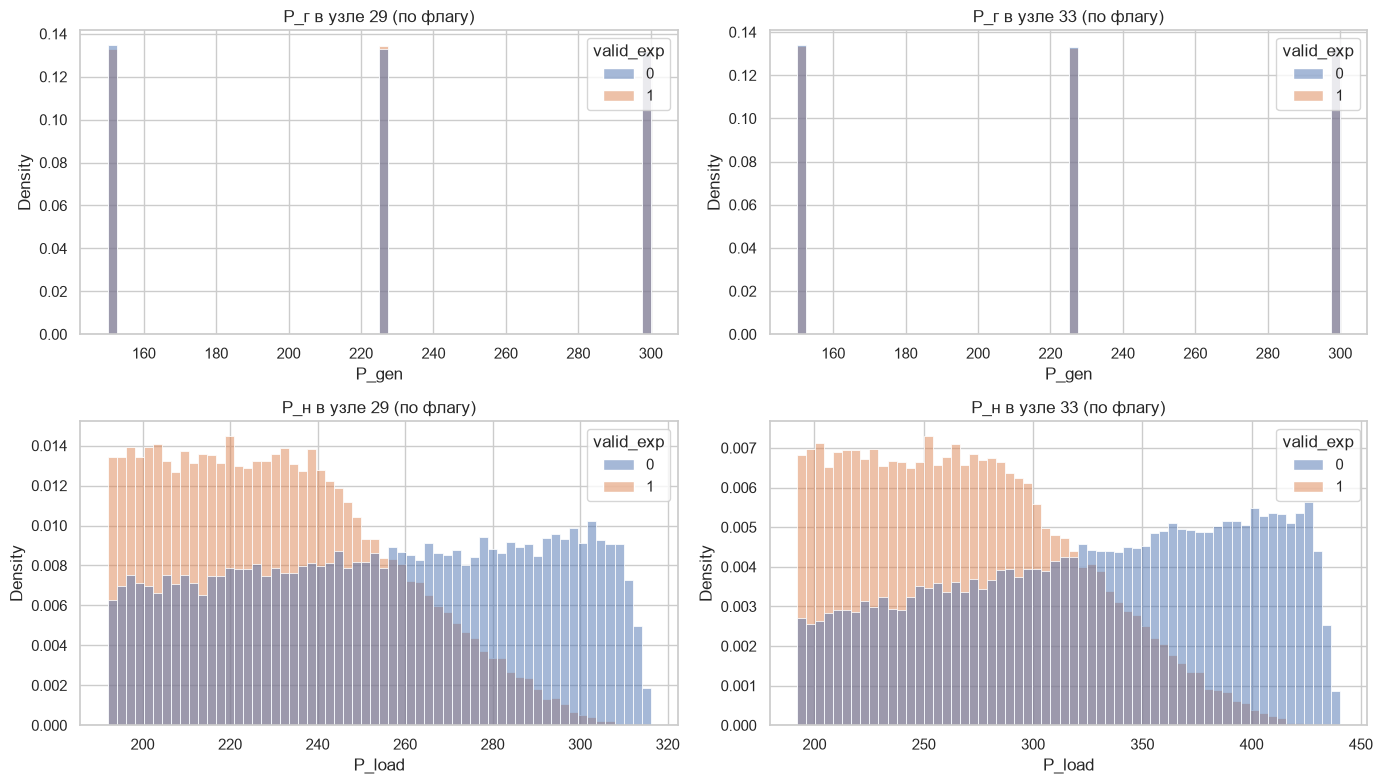

corr(P_gen_29, P_gen_33): -0.0019
P_gen!=0 одновременно в 29 и 33: 1.0


node,29,33
count,"100,000.0000","100,000.0000"
mean,224.7825,224.9250
std,61.2010,61.2969
min,150.0000,150.0000
25%,150.0000,150.0000
50%,225.0000,225.0000
75%,300.0000,300.0000
max,300.0000,300.0000


In [12]:
sel = [n for n in (29, 33) if n in nodes.node.unique()]
fig, ax = plt.subplots(2, len(sel), figsize=(7 * len(sel), 8), squeeze=False)
for j, n in enumerate(sel):
    d = nodes[nodes.node == n]
    sns.histplot(data=d, x="P_gen", hue="valid_exp", bins=60, ax=ax[0, j], stat="density", common_norm=False)
    ax[0, j].set_title(f"P_г в узле {n} (по флагу)")
    sns.histplot(data=d, x="P_load", hue="valid_exp", bins=60, ax=ax[1, j], stat="density", common_norm=False)
    ax[1, j].set_title(f"P_н в узле {n} (по флагу)")
plt.tight_layout(); plt.show()

# P_г в 29 и 33 одновременно - есть ли связь между узлами
if len(sel) == 2:
    pg = nodes[nodes.node.isin(sel)].pivot(index="id", columns="node", values="P_gen")
    print("corr(P_gen_29, P_gen_33):", pg.corr().iloc[0, 1].round(4))
    print("P_gen!=0 одновременно в 29 и 33:", ((pg[29] != 0) & (pg[33] != 0)).mean().round(4))
    display(pg.describe())

In [13]:
# Баланс мощности по опыту и поиск балансирующего узла
bal = nodes.groupby("id").agg(P_load=("P_load", "sum"), P_gen=("P_gen", "sum"),
                              valid=("valid_exp", "first"))
bal["P_gen_minus_load"] = bal.P_gen - bal.P_load
display(bal.groupby("valid")[["P_load", "P_gen", "P_gen_minus_load"]].describe().T)

# узлы с (почти) фиксированным V_pu среди валидных - кандидаты на PV/балансирующий узел
v_ok = nodes[nodes.valid_exp == 1].groupby("node").V_pu.agg(["mean", "std", "min", "max"])
print("Узлы с наименьшим разбросом V_pu (валидные режимы):")
display(v_ok.sort_values("std").head(8))

valid                            0           1
P_load           count 49,915.0000 50,085.0000
                 mean   4,138.3007  3,560.6223
                 std      152.4136    216.4033
                 min    3,647.5400  2,979.5750
                 25%    4,032.3035  3,389.3120
                 50%    4,127.9090  3,554.3700
                 75%    4,234.9980  3,729.1730
                 max    4,882.5020  4,176.5480
P_gen            count 49,915.0000 50,085.0000
                 mean     449.3254  2,701.3774
                 std       86.5954    172.4120
                 min      300.0000  2,112.5250
                 25%      375.0000  2,578.9660
                 50%      450.0000  2,703.8550
                 75%      525.0000  2,826.8000
                 max      600.0000  3,232.1500
P_gen_minus_load count 49,915.0000 50,085.0000
                 mean  -3,688.9754   -859.2449
                 std      175.6793    112.1794
                 min   -4,507.5020 -1,240.4770
                 25%   -3,804.2240   -935.9070
                 50%   -3,682.4430   -855.7320
                 75%   -3,567.1315   -779.7980
                 max   -3,106.9170   -584.7720

Узлы с наименьшим разбросом V_pu (валидные режимы):


,mean,std,min,max
node,,,,
2,1.0200,0.0000,1.0200,1.0200
4,1.0200,0.0000,1.0200,1.0200
7,1.0200,0.0000,1.0200,1.0200
13,1.0455,0.0000,1.0455,1.0455
999,1.0200,0.0000,1.0200,1.0200
12,1.0623,0.0001,1.0621,1.0624
1,1.0200,0.0004,0.9981,1.0200
8,1.0565,0.0019,1.0491,1.0600


### 3.1. Роли узлов

29 и 33 - производители, -1 (999) - балансировщик, остальные - потребители/транзит. Проверяем, что данные это подтверждают.

In [14]:
GENS = [29, 33]
role = pd.Series("consumer/transit", index=sorted(nodes.node.unique()))
role.loc[[n for n in GENS if n in role.index]] = "generator"
role.loc[REF] = "balancer"
nodes["role"] = nodes.node.map(role)

by_role = nodes.groupby("role").agg(
    nodes=("node", "nunique"),
    P_gen_nonzero=("P_gen", lambda s: (s != 0).mean()), P_gen_mean=("P_gen", "mean"),
    P_load_nonzero=("P_load", lambda s: (s != 0).mean()), P_load_mean=("P_load", "mean"),
    Q_load_nonzero=("Q_load", lambda s: (s != 0).mean()))
display(by_role)

unexpected = gen[(gen.P_gen_nonzero_share > 0) & ~gen.index.isin(GENS + [REF])]
print("Генерация вне 29/33/балансировщика:", unexpected.index.tolist() or "нет (роли подтверждены)")

# узлы без мощности вообще (транзитные, "на них ничего не происходит")
active = nodes.groupby("node")[["P_load", "Q_load", "P_gen"]].agg(lambda s: (s != 0).any()).any(axis=1)
print("Узлы без нагрузки и генерации ни в одном опыте:", active[~active].index.tolist())

,nodes,P_gen_nonzero,P_gen_mean,P_load_nonzero,P_load_mean,Q_load_nonzero
role,,,,,,
consumer/transit,33,0.0152,34.1684,0.5455,100.1956,0.5455
generator,2,1.0000,224.8537,1.0000,271.2571,1.0000


Генерация вне 29/33/балансировщика: [999]
Узлы без нагрузки и генерации ни в одном опыте: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 15, 18, 19]


## 4. Разделение на valid = 1 / valid = 0

In [15]:
v1 = nodes[nodes.valid_exp == 1]; v0 = nodes[nodes.valid_exp == 0]
print("Строк узлов valid=1:", len(v1), "| valid=0:", len(v0))

cols = ["P_load", "Q_load", "P_gen", "V", "V_pu", "Delta"]
display(pd.concat({"valid=1": v1[cols].describe().T, "valid=0": v0[cols].describe().T}, axis=1))

# что лежит в V/Delta у невалидных опытов: нули, NaN или мусор?
for c in ["V", "Delta"]:
    print(f"{c}: valid=0 -> NaN {v0[c].isna().mean():.3f}, нули {(v0[c]==0).mean():.3f}; "
          f"valid=1 -> NaN {v1[c].isna().mean():.3f}, нули {(v1[c]==0).mean():.3f}")

Строк узлов valid=1: 1752975 | valid=0: 1747025


valid=1                                                                         valid=0                                                          
                count     mean      std      min      25%      50%      75%        max          count     mean      std    min    25%     50%      75%      max
P_load 1,752,975.0000 101.7321 123.6709   0.0000   0.0000  20.5230 198.1280   638.3230 1,747,025.0000 118.2372 147.8598 0.0000 0.0000 23.2530 225.7930 660.7820
Q_load 1,752,975.0000  50.7994  64.5863   0.0000   0.0000  10.2620  98.5550   324.3920 1,747,025.0000  58.9203  76.1053 0.0000 0.0000 11.6270 112.8070 325.1540
P_gen  1,752,975.0000  77.1822 377.6193   0.0000   0.0000   0.0000   0.0000 2,689.0170 1,747,025.0000  12.8379  54.1661 0.0000 0.0000  0.0000   0.0000 300.0000
V      1,752,975.0000 223.1910 156.9279  56.0480  96.1820 185.7530 233.6940   510.0000 1,747,025.0000   0.0000   0.0000 0.0000 0.0000  0.0000   0.0000   0.0000
V_pu   1,752,975.0000   0.9086   0.0942   0.5095   0.8440   0.9051   1.0020     1.0624 1,747,025.0000   0.0000   0.0000 0.0000 0.0000  0.0000   0.0000   0.0000
Delta  1,752,975.0000 -25.1013  12.3453 -58.2530 -34.3180 -29.2670 -15.2370     0.0000 1,747,025.0000   0.0000   0.0000 0.0000 0.0000  0.0000   0.0000   0.0000

V: valid=0 -> NaN 0.000, нули 1.000; valid=1 -> NaN 0.000, нули 0.000
Delta: valid=0 -> NaN 0.000, нули 1.000; valid=1 -> NaN 0.000, нули 0.029


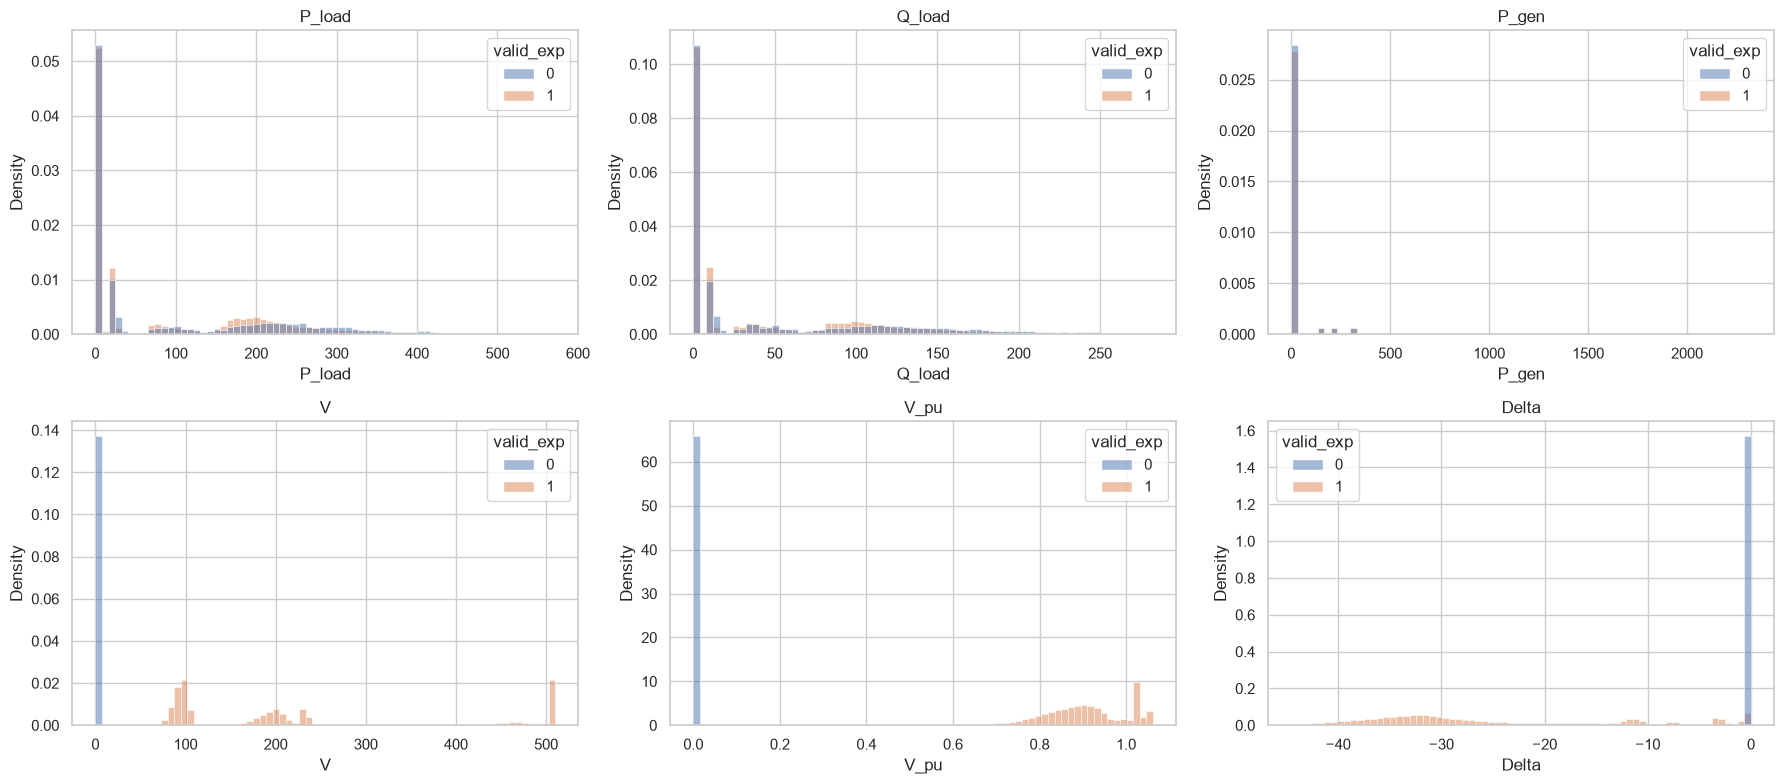

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for a, c in zip(ax.ravel(), cols):
    d = nodes[[c, "valid_exp"]].replace([np.inf, -np.inf], np.nan).dropna()
    lo, hi = d[c].quantile([.005, .995])
    sns.histplot(data=d[d[c].between(lo, hi)], x=c, hue="valid_exp", bins=70, stat="density",
                 common_norm=False, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

## 5. Линии

Что **константа** по опытам (топология/параметры), а что **меняется** (результат расчёта)?

In [17]:
static_cols = ["n_s", "n_e", "type", "R", "X", "B", "Kt", "I_dop"]
nun = lines.groupby("line")[static_cols].nunique()
print("Число линий:", lines.line.nunique())
print("Колонки, у которых значение меняется между опытами хотя бы у одной линии:")
print((nun > 1).sum()[lambda s: s > 0] if (nun > 1).any().any() else "все параметры строго постоянны")

line_info = lines.groupby("line")[["n_s", "n_e", "type", "R", "X", "B", "Kt", "I_dop"]].first()
display(line_info.head(15))
print("\nТипы ветвей:"); print(lines.groupby("type").agg(n_lines=("line", "nunique"),
      R=("R", "mean"), X=("X", "mean"), B=("B", "mean"), Kt=("Kt", "mean")))

Число линий: 80
Колонки, у которых значение меняется между опытами хотя бы у одной линии:
I_dop    80
dtype: int64


,n_s,n_e,type,R,X,B,Kt,I_dop
line,,,,,,,,
1,-1,3,0,2.9600,45.6000,-546.8000,0.0000,"3,003.1000"
2,-1,4,0,1.1800,18.2400,-218.7000,0.0000,"3,003.1000"
3,15,16,0,1.1000,6.3000,-40.5000,0.0000,824.9000
4,16,22,1,0.5700,29.0900,18.8000,0.5050,478.7000
5,10,15,0,1.4600,8.4000,-54.0000,0.0000,825.0000
6,15,23,1,0.4400,23.2700,23.5000,0.5050,600.0000
7,10,17,0,1.1000,6.3000,-40.5000,0.0000,825.3000
8,10,11,0,1.9200,8.5800,-52.9000,0.0000,709.1000
9,10,11,0,1.9200,8.5800,-52.9000,0.0000,709.1000



Типы ветвей:
      n_lines      R       X         B     Kt
type                                         
0          56 4.9405 28.9971 -277.4464 0.0000
1          24 0.6479 34.4562   16.4292 0.4900


In [18]:
# Соотношение I_zarg = I_max / I_dop * 100 ?
chk = lines[lines.I_dop > 0].copy()
chk["I_zarg_calc"] = chk.I_max / chk.I_dop * 100
chk["err"] = (chk.I_zarg - chk.I_zarg_calc).abs()
print("max |I_zarg - I_max/I_dop*100| (valid):", chk[chk.valid_exp == 1].err.max())
print("I_zarg > 100 % (перегрузка), доля среди valid:", (lines[lines.valid_exp == 1].I_zarg > 100).mean().round(4))

print("\nТоки по флагу:")
display(lines.groupby("valid_exp")[["I_max", "I_zarg"]].describe().T)
for c in ["I_max", "I_zarg"]:
    print(c, "valid=0: NaN", lines[lines.valid_exp == 0][c].isna().mean().round(3),
          "| нули", (lines[lines.valid_exp == 0][c] == 0).mean().round(3))

max |I_zarg - I_max/I_dop*100| (valid): 0.027290903032366032
I_zarg > 100 % (перегрузка), доля среди valid: 0.0415

Токи по флагу:


valid_exp         0              1
I_max  count 0.0000 4,006,800.0000
       mean     NaN       378.6474
       std      NaN       283.0962
       min      NaN         6.7000
       25%      NaN       152.9000
       50%      NaN       322.9000
       75%      NaN       502.4000
       max      NaN     1,766.0000
I_zarg count 0.0000 4,006,800.0000
       mean     NaN        46.5580
       std      NaN        29.7943
       min      NaN         1.0000
       25%      NaN        19.6000
       50%      NaN        41.4000
       75%      NaN        71.1000
       max      NaN       185.4000

I_max valid=0: NaN 1.0 | нули 0.0
I_zarg valid=0: NaN 1.0 | нули 0.0


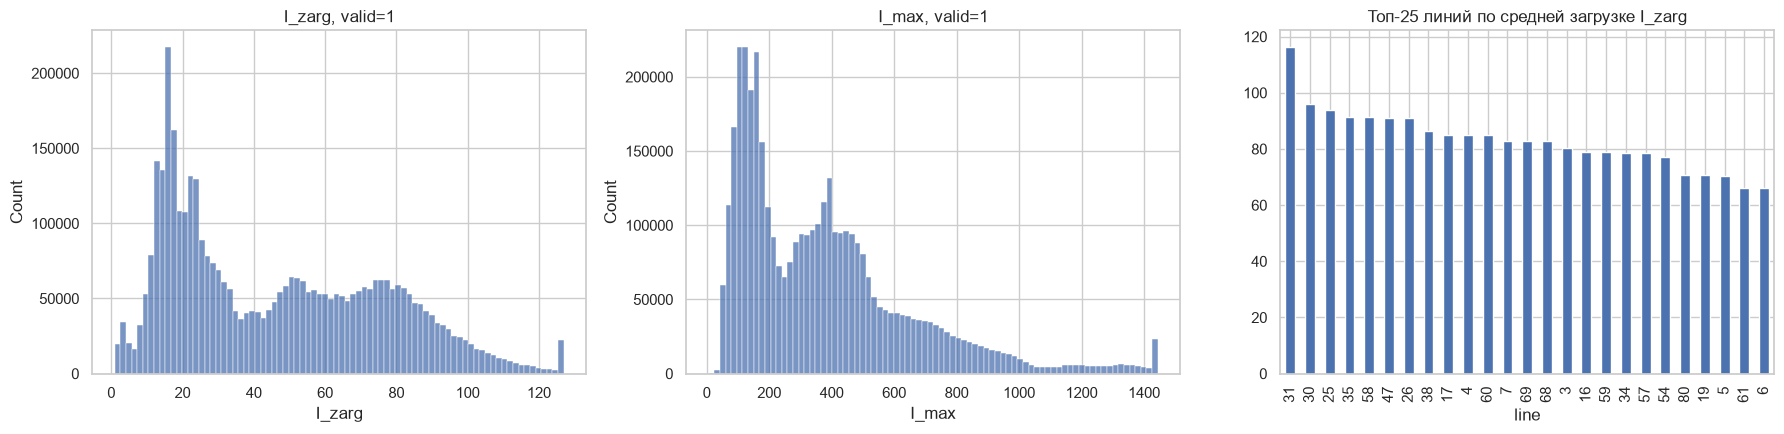

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
d = lines[lines.valid_exp == 1]
sns.histplot(d.I_zarg.clip(0, d.I_zarg.quantile(.995)), bins=80, ax=ax[0]); ax[0].set_title("I_zarg, valid=1")
sns.histplot(d.I_max.clip(0, d.I_max.quantile(.995)), bins=80, ax=ax[1]); ax[1].set_title("I_max, valid=1")
d.groupby("line").I_zarg.mean().sort_values(ascending=False).head(25).plot.bar(ax=ax[2])
ax[2].set_title("Топ-25 линий по средней загрузке I_zarg")
plt.tight_layout(); plt.show()

## 6. Корреляции: входы → выходы

Строим «широкие» таблицы: 1 строка = 1 опыт, колонки = `<признак>_<номер узла/линии>`.

* **Входы:** `P_load`, `Q_load`, `P_gen` по узлам (+ параметры линий, если они меняются)
* **Выходы:** `V_pu`, `Delta` по узлам; `I_max`, `I_zarg` по линиям

In [20]:
def wide(df, cols, key):
    w = df.set_index(["id", key])[cols].unstack(key)
    w.columns = [f"{a}_{b}" for a, b in w.columns]
    return w

node_in  = wide(nodes, ["P_load", "Q_load", "P_gen"], "node")
node_out = wide(nodes, ["V_pu", "Delta"], "node")
line_out = wide(lines, ["I_max", "I_zarg"], "line")

# параметры линий включаем как вход только если они реально меняются между опытами
varying = [c for c in ["R", "X", "B", "Kt", "I_dop"] if (lines.groupby("line")[c].nunique() > 1).any()]
line_in = wide(lines, varying, "line") if varying else pd.DataFrame(index=node_in.index)
print("Меняющиеся параметры линий:", varying or "нет (топология/параметры постоянны)")

ok = exp_valid[exp_valid == 1].index
drop_const = lambda df: df.loc[:, df.std() > 0]
X_nodes = drop_const(node_in.loc[ok])
Y_V     = drop_const(node_out.loc[ok, [c for c in node_out if c.startswith("V_pu")]])
Y_D     = drop_const(node_out.loc[ok, [c for c in node_out if c.startswith("Delta")]])
Y_I     = drop_const(line_out.loc[ok, [c for c in line_out if c.startswith("I_zarg")]])
print(X_nodes.shape, Y_V.shape, Y_D.shape, Y_I.shape)

Меняющиеся параметры линий: ['I_dop']
(50085, 43) (50085, 35) (50085, 34) (50085, 80)


In [21]:
def cross_corr(X, Y, method="pearson"):
    return pd.concat([X, Y], axis=1).corr(method=method).loc[X.columns, Y.columns]

def top_pairs(c, k=30):
    s = c.stack().rename("corr").reset_index()
    s.columns = ["x", "y", "corr"]
    s["abs"] = s["corr"].abs()
    return s.sort_values("abs", ascending=False).head(k).reset_index(drop=True)

def heat(c, title, figsize=(13, 10)):
    plt.figure(figsize=figsize)
    sns.heatmap(c, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.2)
    plt.title(title); plt.tight_layout(); plt.show()

C_V = cross_corr(X_nodes, Y_V)
C_D = cross_corr(X_nodes, Y_D)
C_I = cross_corr(X_nodes, Y_I)

print("Топ связей вход -> V_pu (valid=1):");  display(top_pairs(C_V, 25))
print("Топ связей вход -> Delta (valid=1):"); display(top_pairs(C_D, 25))
print("Топ связей вход -> I_zarg (valid=1):"); display(top_pairs(C_I, 25))

Топ связей вход -> V_pu (valid=1):


,x,y,corr,abs
0,P_gen_999,V_pu_3,-0.9254,0.9254
1,P_gen_999,V_pu_17,-0.9191,0.9191
2,P_gen_999,V_pu_5,-0.9191,0.9191
3,P_gen_999,V_pu_6,-0.9186,0.9186
4,P_gen_999,V_pu_15,-0.9177,0.9177
5,P_gen_999,V_pu_10,-0.9176,0.9176
6,P_gen_999,V_pu_23,-0.9165,0.9165
7,P_gen_999,V_pu_9,-0.9158,0.9158
8,P_gen_999,V_pu_34,-0.9153,0.9153
9,P_gen_999,V_pu_16,-0.9152,0.9152


Топ связей вход -> Delta (valid=1):


,x,y,corr,abs
0,P_gen_999,Delta_3,-0.9925,0.9925
1,P_gen_999,Delta_9,-0.9889,0.9889
2,P_gen_999,Delta_4,-0.9867,0.9867
3,P_gen_999,Delta_2,-0.9866,0.9866
4,P_gen_999,Delta_7,-0.9828,0.9828
5,P_gen_999,Delta_8,-0.9805,0.9805
6,P_gen_999,Delta_1,-0.9788,0.9788
7,P_gen_999,Delta_5,-0.9730,0.9730
8,P_gen_999,Delta_6,-0.9726,0.9726
9,P_gen_999,Delta_10,-0.9639,0.9639


Топ связей вход -> I_zarg (valid=1):


,x,y,corr,abs
0,P_gen_999,I_zarg_1,0.9893,0.9893
1,P_gen_999,I_zarg_2,0.9865,0.9865
2,P_gen_999,I_zarg_39,0.9845,0.9845
3,P_load_27,I_zarg_23,0.9812,0.9812
4,Q_load_27,I_zarg_23,0.9812,0.9812
5,P_gen_999,I_zarg_52,0.9761,0.9761
6,P_gen_999,I_zarg_51,0.9731,0.9731
7,Q_load_20,I_zarg_21,0.9574,0.9574
8,Q_load_20,I_zarg_71,0.9574,0.9574
9,P_load_20,I_zarg_21,0.9574,0.9574


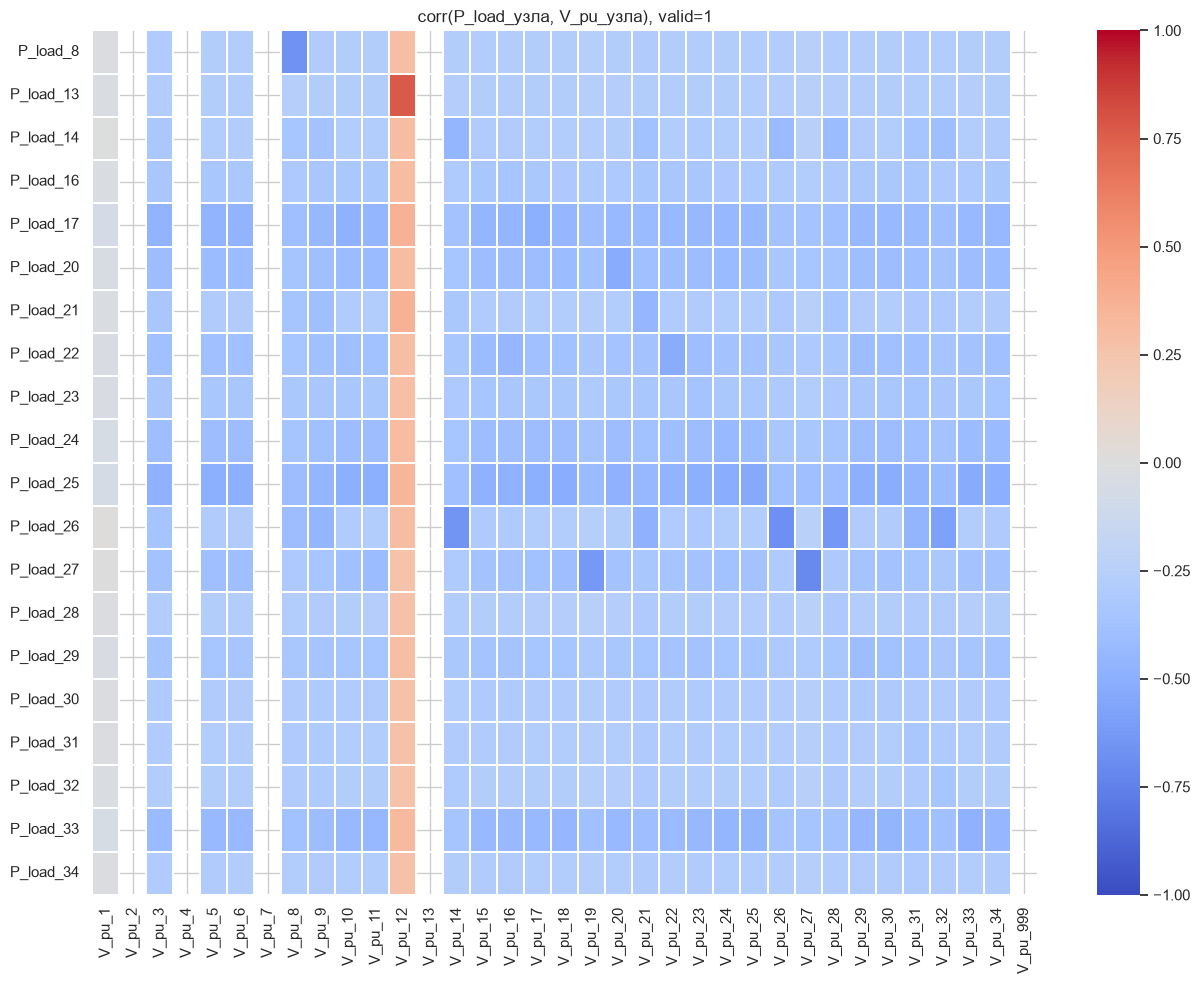

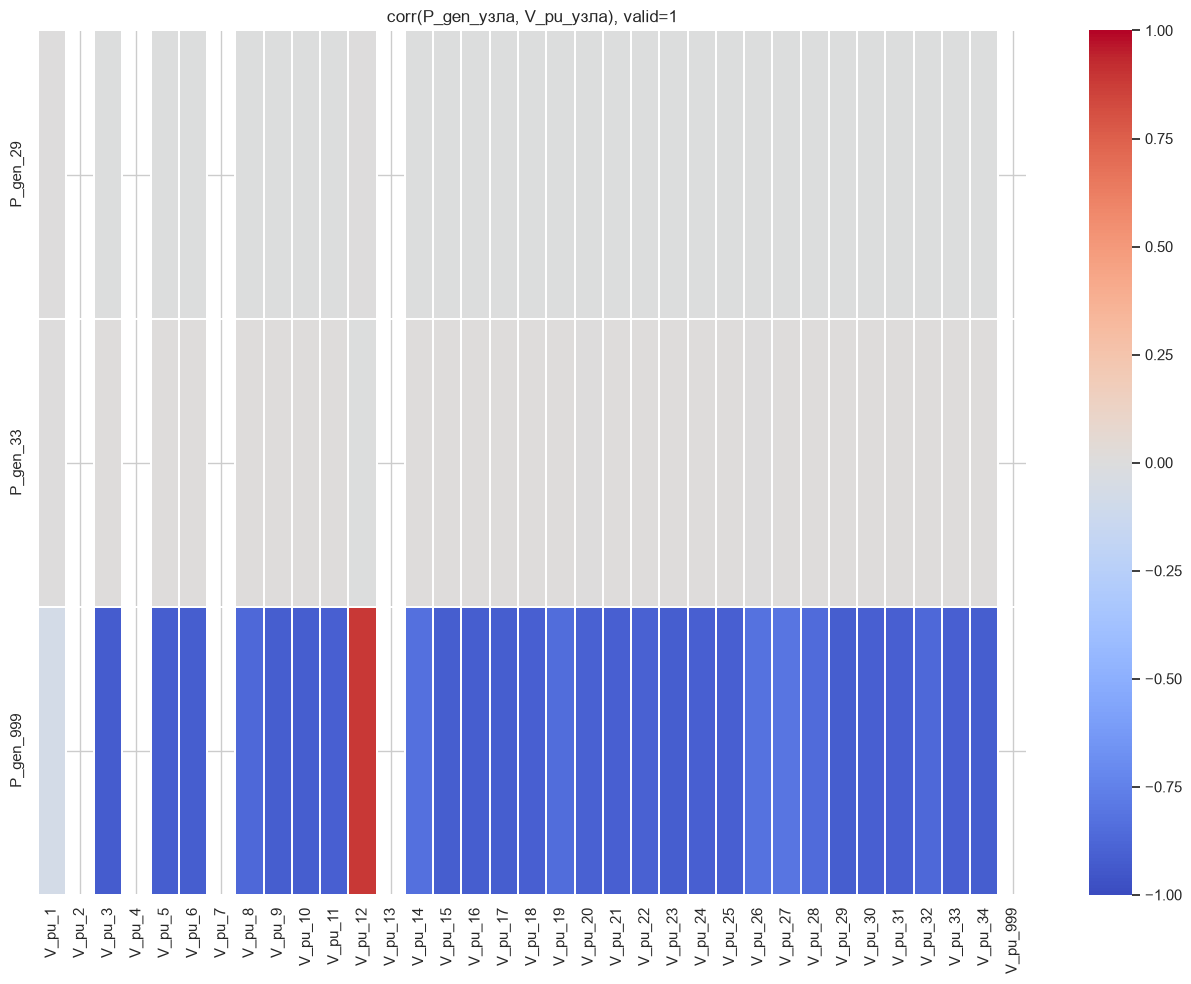

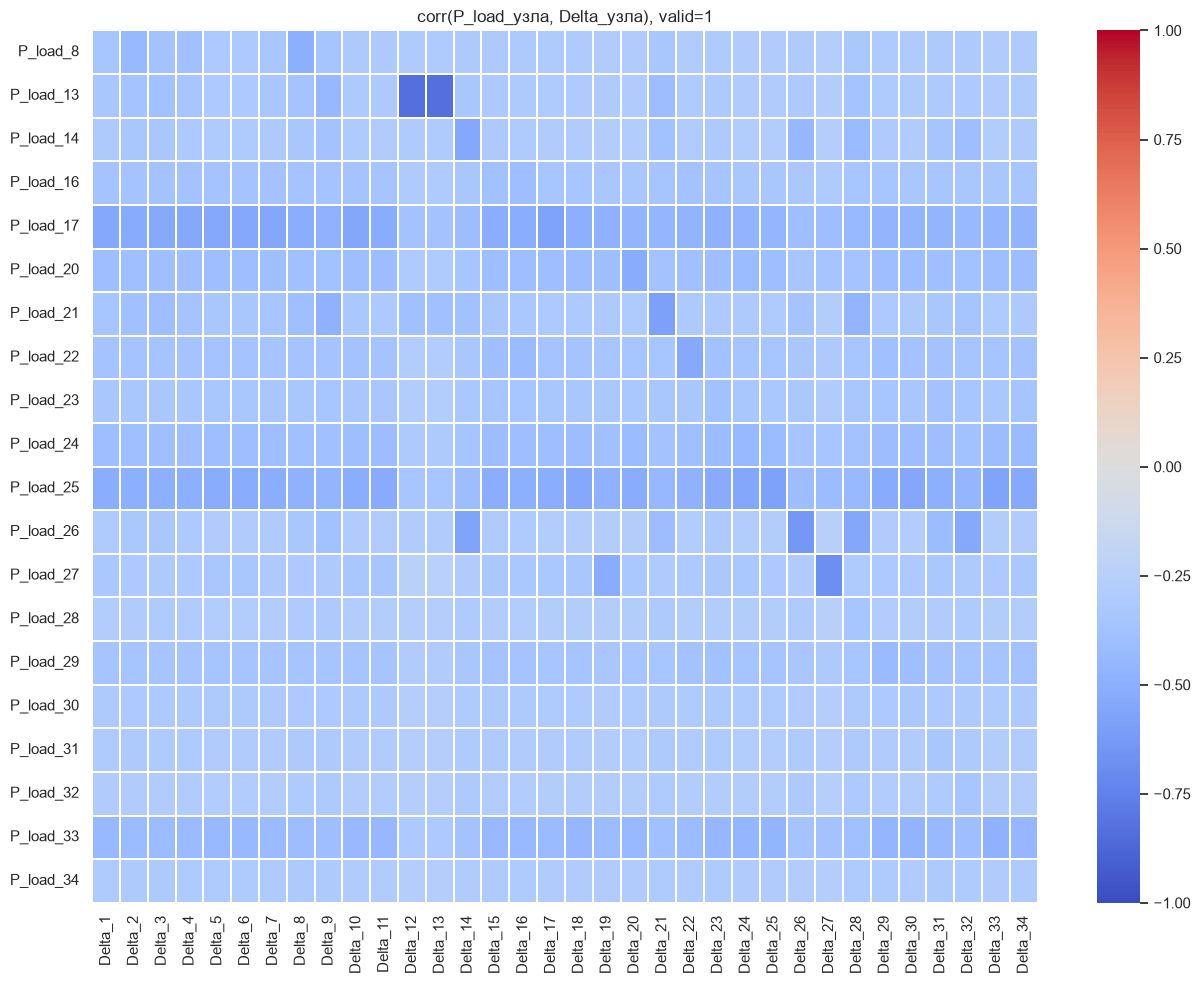

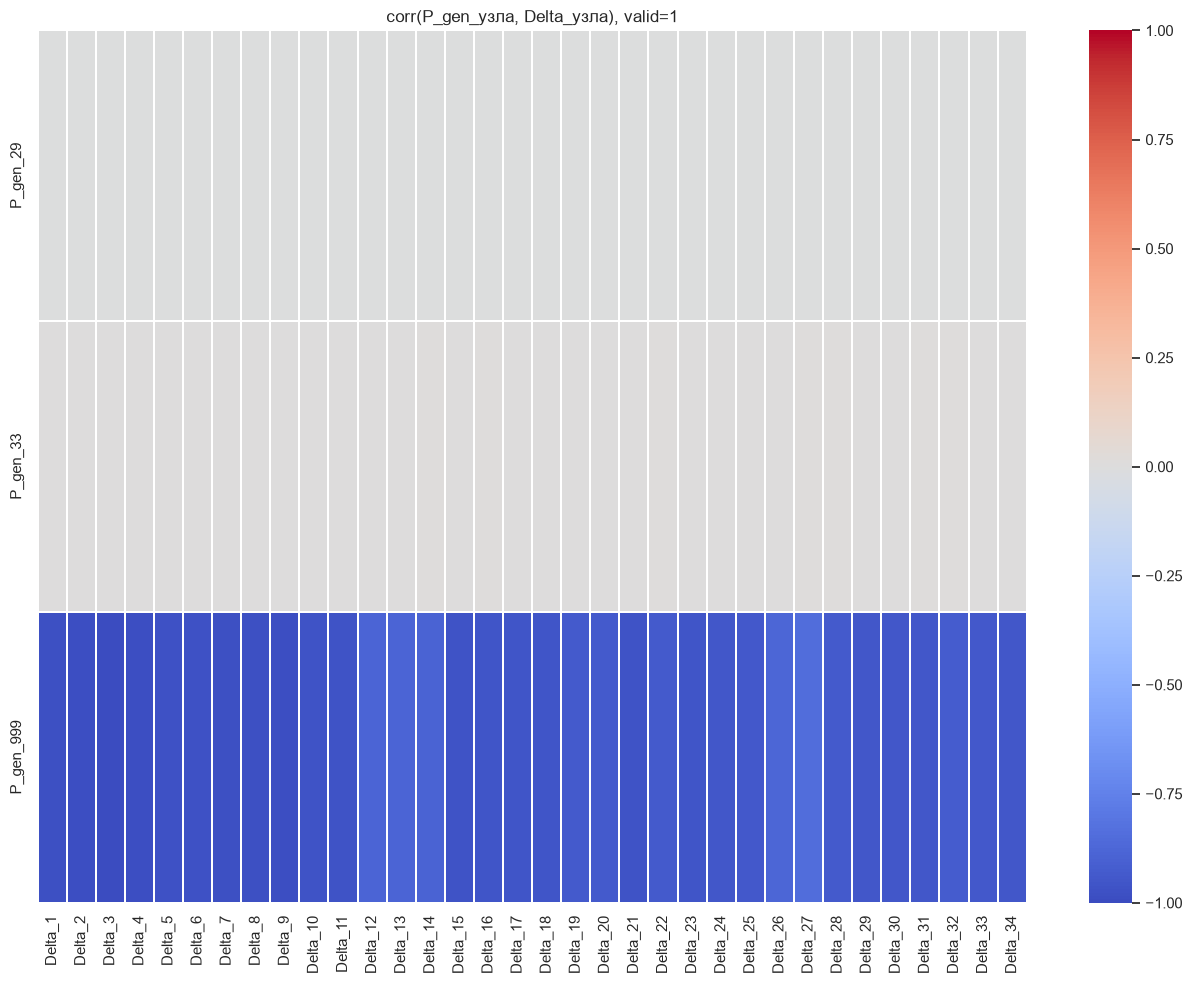

In [22]:
for prefix, C, name in [("P_load", C_V, "V_pu"), ("P_gen", C_V, "V_pu"),
                        ("P_load", C_D, "Delta"), ("P_gen", C_D, "Delta")]:
    rows = [r for r in C.index if r.startswith(prefix)]
    heat(C.loc[rows], f"corr({prefix}_узла, {name}_узла), valid=1")

In [23]:
# Какие входные группы вообще объясняют выходы: средняя |corr| по типу входа
summary = pd.DataFrame({
    "->V_pu":  [C_V.loc[[r for r in C_V.index if r.startswith(p)]].abs().mean().mean() for p in ["P_load", "Q_load", "P_gen"]],
    "->Delta": [C_D.loc[[r for r in C_D.index if r.startswith(p)]].abs().mean().mean() for p in ["P_load", "Q_load", "P_gen"]],
    "->I_zarg":[C_I.loc[[r for r in C_I.index if r.startswith(p)]].abs().mean().mean() for p in ["P_load", "Q_load", "P_gen"]],
}, index=["P_load", "Q_load", "P_gen"])
display(summary)

,->V_pu,->Delta,->I_zarg
P_load,0.3325,0.3532,0.2632
Q_load,0.3325,0.3532,0.2632
P_gen,0.2930,0.3191,0.2252


### 6.2. Линии ↔ узлы: что на что влияет

In [24]:
# (а) Если параметры линий меняются - их связь с V, Delta, I
if varying:
    Xl = drop_const(line_in.loc[ok])
    C_lV = cross_corr(Xl, Y_V); C_lD = cross_corr(Xl, Y_D); C_lI = cross_corr(Xl, Y_I)
    print("параметры линий -> V_pu");  display(top_pairs(C_lV, 20))
    print("параметры линий -> Delta"); display(top_pairs(C_lD, 20))
    print("параметры линий -> I_zarg"); display(top_pairs(C_lI, 20))
else:
    print("Параметры линий константны -> влияют только через структуру сети (топологию), "
          "а в данных различаются лишь нагрузки/генерация.")

параметры линий -> V_pu


,x,y,corr,abs
0,I_dop_43,V_pu_12,-0.0661,0.0661
1,I_dop_43,V_pu_6,0.0621,0.0621
2,I_dop_43,V_pu_33,0.0621,0.0621
3,I_dop_43,V_pu_24,0.0621,0.0621
4,I_dop_43,V_pu_18,0.0620,0.0620
5,I_dop_43,V_pu_5,0.0620,0.0620
6,I_dop_43,V_pu_20,0.0620,0.0620
7,I_dop_43,V_pu_17,0.0620,0.0620
8,I_dop_43,V_pu_30,0.0620,0.0620
9,I_dop_43,V_pu_25,0.0619,0.0619


параметры линий -> Delta


,x,y,corr,abs
0,I_dop_43,Delta_7,0.0770,0.0770
1,I_dop_43,Delta_3,0.0744,0.0744
2,I_dop_43,Delta_4,0.0742,0.0742
3,I_dop_43,Delta_1,0.0729,0.0729
4,I_dop_43,Delta_6,0.0728,0.0728
5,I_dop_43,Delta_5,0.0726,0.0726
6,I_dop_43,Delta_9,0.0710,0.0710
7,I_dop_43,Delta_2,0.0708,0.0708
8,I_dop_43,Delta_11,0.0706,0.0706
9,I_dop_43,Delta_10,0.0704,0.0704


параметры линий -> I_zarg


,x,y,corr,abs
0,I_dop_51,I_zarg_51,-0.1323,0.1323
1,I_dop_43,I_zarg_52,-0.0791,0.0791
2,I_dop_43,I_zarg_2,-0.0741,0.0741
3,I_dop_43,I_zarg_51,-0.0736,0.0736
4,I_dop_43,I_zarg_48,-0.0730,0.0730
5,I_dop_43,I_zarg_1,-0.0719,0.0719
6,I_dop_43,I_zarg_27,-0.0706,0.0706
7,I_dop_43,I_zarg_39,-0.0691,0.0691
8,I_dop_43,I_zarg_43,-0.0687,0.0687
9,I_dop_43,I_zarg_37,-0.0676,0.0676


In [25]:
# (б) Физическая проверка: ток линии vs напряжения/углы на концах.
# Эталонный узел (-1, в линиях 999) не отбрасываем: у него есть V/Delta в таблице узлов,
# поэтому линии к нему считаются так же, как все остальные.
li = line_info.reset_index()
vp = node_out.loc[ok]
res = []
for r in li.itertuples(index=False):
    cI = f"I_max_{r.line}"
    if cI not in line_out: continue
    I = line_out.loc[ok, cI]
    Vs, Ve = vp.get(f"V_pu_{r.n_s}"), vp.get(f"V_pu_{r.n_e}")
    Ds, De = vp.get(f"Delta_{r.n_s}"), vp.get(f"Delta_{r.n_e}")
    both = Vs is not None and Ve is not None
    res.append({"line": r.line, "n_s": r.n_s, "n_e": r.n_e, "type": r.type, "X": r.X,
                "has_ref": REF in (r.n_s, r.n_e),
                "corr(I,|dDelta|)": I.corr((Ds - De).abs()) if both else np.nan,
                "corr(I,|dV|)":     I.corr((Vs - Ve).abs()) if both else np.nan,
                "corr(I,V_ns)": I.corr(Vs) if Vs is not None else np.nan,
                "corr(I,V_ne)": I.corr(Ve) if Ve is not None else np.nan,
                "corr(I,Delta_ns)": I.corr(Ds) if Ds is not None else np.nan,
                "corr(I,Delta_ne)": I.corr(De) if De is not None else np.nan})
phys = pd.DataFrame(res).set_index("line")
display(phys.sort_values("corr(I,|dDelta|)", ascending=False))

,n_s,n_e,type,X,has_ref,"corr(I,|dDelta|)","corr(I,|dV|)","corr(I,V_ns)","corr(I,V_ne)","corr(I,Delta_ns)","corr(I,Delta_ne)"
line,,,,,,,,,,,
52,4,7,0,48.6400,False,1.0000,NaN,-0.0000,-0.0000,-0.9936,-0.9987
39,2,4,0,91.8000,False,1.0000,NaN,0.0000,0.0000,-0.9996,-0.9955
48,1,2,0,114.0000,False,0.9998,0.0881,-0.0881,0.0000,-0.9881,-0.9640
53,12,13,0,12.8000,False,0.9998,0.9621,0.9621,0.0000,-0.9998,-0.9998
47,5,10,1,35.8900,False,0.9996,0.9558,-0.9944,-0.9945,-0.9886,-0.9949
26,5,10,1,35.8900,False,0.9996,0.9558,-0.9944,-0.9945,-0.9886,-0.9949
30,6,11,1,35.8900,False,0.9986,0.9520,-0.9954,-0.9965,-0.9771,-0.9883
23,24,27,0,33.0400,False,0.9986,0.9905,-0.3460,-0.6935,-0.2794,-0.6606
27,3,5,0,58.0500,False,0.9983,0.9908,-0.9781,-0.9895,-0.9639,-0.9912


In [26]:
# (в) Связь I_zarg линий с мощностью узлов на его концах
res = []
for r in li.itertuples(index=False):
    c = f"I_zarg_{r.line}"
    if c not in line_out: continue
    I = line_out.loc[ok, c]
    row = {"line": r.line, "n_s": r.n_s, "n_e": r.n_e}
    for p in ["P_load", "P_gen"]:
        for side in ["n_s", "n_e"]:
            col = f"{p}_{getattr(r, side)}"
            row[f"corr(I_zarg,{p}@{side})"] = I.corr(node_in.loc[ok, col]) if col in node_in and node_in.loc[ok, col].std() > 0 else np.nan
    res.append(row)
display(pd.DataFrame(res).set_index("line").sort_values("corr(I_zarg,P_load@n_s)", key=abs, ascending=False).head(30))

,n_s,n_e,"corr(I_zarg,P_load@n_s)","corr(I_zarg,P_load@n_e)","corr(I_zarg,P_gen@n_s)","corr(I_zarg,P_gen@n_e)"
line,,,,,,
71,20,24,0.9574,-0.0634,NaN,NaN
21,20,24,0.9574,-0.0634,NaN,NaN
46,22,29,0.9014,-0.2122,NaN,-0.0028
77,22,29,0.9014,-0.2122,NaN,-0.0028
11,26,31,0.8564,0.0539,NaN,NaN
10,26,28,0.7725,0.1878,NaN,NaN
79,26,28,0.7725,0.1878,NaN,NaN
74,25,33,0.6446,-0.6293,NaN,-0.0000
20,25,33,0.6446,-0.6293,NaN,-0.0000


### 6.3. Эталонный узел -1 (в линиях 999)

Линии, подключённые к эталонному узлу, берут на себя небаланс режима. Смотрим их параметры, токи и связь с входами и с системным балансом.

In [27]:
# Сам эталонный узел (-1): V, Delta, мощности - по флагу
ref_nodes = nodes[nodes.node == REF]
display(ref_nodes.groupby("valid_exp")[["U_nom", "V", "V_pu", "Delta", "P_load", "Q_load", "P_gen"]].describe().T)
print("V_pu в REF: уникальных значений (valid=1):", ref_nodes[ref_nodes.valid_exp == 1].V_pu.round(4).nunique())
print("Delta в REF: уникальных значений (valid=1):", ref_nodes[ref_nodes.valid_exp == 1].Delta.round(4).nunique())

Empty DataFrame
Columns: []
Index: [(U_nom, count), (U_nom, mean), (U_nom, std), (U_nom, min), (U_nom, 25%), (U_nom, 50%), (U_nom, 75%), (U_nom, max), (V, count), (V, mean), (V, std), (V, min), (V, 25%), (V, 50%), (V, 75%), (V, max), (V_pu, count), (V_pu, mean), (V_pu, std), (V_pu, min), (V_pu, 25%), (V_pu, 50%), (V_pu, 75%), (V_pu, max), (Delta, count), (Delta, mean), (Delta, std), (Delta, min), (Delta, 25%), (Delta, 50%), (Delta, 75%), (Delta, max), (P_load, count), (P_load, mean), (P_load, std), (P_load, min), (P_load, 25%), (P_load, 50%), (P_load, 75%), (P_load, max), (Q_load, count), (Q_load, mean), (Q_load, std), (Q_load, min), (Q_load, 25%), (Q_load, 50%), (Q_load, 75%), (Q_load, max), (P_gen, count), (P_gen, mean), (P_gen, std), (P_gen, min), (P_gen, 25%), (P_gen, 50%), (P_gen, 75%), (P_gen, max)]

V_pu в REF: уникальных значений (valid=1): 0
Delta в REF: уникальных значений (valid=1): 0


In [28]:
ref_lines = line_info[(line_info.n_s == REF) | (line_info.n_e == REF)]
print("Линии, подключённые к эталонному узлу:", len(ref_lines))
display(ref_lines)

rl = ref_lines.index.tolist()
print("\nТоки этих линий по флагу:")
display(lines[lines.line.isin(rl)].groupby(["line", "valid_exp"])[["I_max", "I_zarg"]].agg(["mean", "std", "max"]))

# какие узлы-соседи 999
neigh = sorted(set(ref_lines.n_s) | set(ref_lines.n_e) - {REF})
neigh = sorted((set(ref_lines.n_s) | set(ref_lines.n_e)) - {REF})
print("Соседи эталонного узла:", neigh)

Линии, подключённые к эталонному узлу: 5


,n_s,n_e,type,R,X,B,Kt,I_dop
line,,,,,,,,
1,-1,3,0,2.9600,45.6000,-546.8000,0.0000,"3,003.1000"
2,-1,4,0,1.1800,18.2400,-218.7000,0.0000,"3,003.1000"
51,-1,7,0,11.8200,182.4000,"-2,187.0000",0.0000,"2,992.2000"
55,-1,12,1,0.5700,35.8900,11.1000,0.4600,882.8000
56,-1,12,1,0.5700,35.8900,11.1000,0.4600,882.8000



Токи этих линий по флагу:


I_max                     I_zarg               
                     mean     std        max    mean    std     max
line valid_exp                                                     
1    0                NaN     NaN        NaN     NaN    NaN     NaN
     1         1,237.8923 76.1444 1,462.5000 41.2630 2.5383 48.7000
2    0                NaN     NaN        NaN     NaN    NaN     NaN
     1           917.9835 56.9460 1,073.1000 30.5996 1.8983 35.8000
51   0                NaN     NaN        NaN     NaN    NaN     NaN
     1           386.9918  6.1965   403.5000 12.8998 0.2084 13.4000
55   0                NaN     NaN        NaN     NaN    NaN     NaN
     1           100.5424 18.3126   167.1000 11.3864 2.0739 18.9000
56   0                NaN     NaN        NaN     NaN    NaN     NaN
     1           100.5424 18.3126   167.1000 11.3864 2.0739 18.9000

Соседи эталонного узла: [3, 4, 7, 12]


In [29]:
# (а) связь токов линий к 999 с узловыми входами (valid=1)
Yr = drop_const(line_out.loc[ok, [f"I_zarg_{l}" for l in rl if f"I_zarg_{l}" in line_out]])
C_ref = cross_corr(X_nodes, Yr)
print("Топ связей: вход узла -> I_zarg линии к 999"); display(top_pairs(C_ref, 30))

# (б) токи в сторону 999 vs системный небаланс (генерация - нагрузка)
agg = pd.DataFrame({
    "sum_P_load": node_in.loc[ok].filter(like="P_load_").sum(axis=1),
    "sum_Q_load": node_in.loc[ok].filter(like="Q_load_").sum(axis=1),
    "sum_P_gen":  node_in.loc[ok].filter(like="P_gen_").sum(axis=1),
})
agg["gen_minus_load"] = agg.sum_P_gen - agg.sum_P_load
for l in rl:
    if f"I_max_{l}" in line_out: agg[f"I_max_line{l}"] = line_out.loc[ok, f"I_max_{l}"]
agg["sum_I_max_ref"] = agg.filter(like="I_max_line").sum(axis=1)
c = agg.corr()
print("Корреляция суммарного тока линий к 999 с балансом системы:")
display(c.loc[["sum_I_max_ref"] + [x for x in c.index if x.startswith("I_max_line")],
              ["sum_P_load", "sum_Q_load", "sum_P_gen", "gen_minus_load"]])

# (в) связь с V/Delta соседних узлов
for n in neigh:
    for nm in (f"V_pu_{n}", f"Delta_{n}"):
        if nm in node_out:
            print(nm, "vs I_max линий к 999:",
                  {l: round(line_out.loc[ok, f"I_max_{l}"].corr(node_out.loc[ok, nm]), 3) for l in rl if f"I_max_{l}" in line_out})

Топ связей: вход узла -> I_zarg линии к 999


,x,y,corr,abs
0,P_gen_999,I_zarg_1,0.9893,0.9893
1,P_gen_999,I_zarg_2,0.9865,0.9865
2,P_gen_999,I_zarg_51,0.9731,0.9731
3,P_gen_999,I_zarg_55,0.8843,0.8843
4,P_gen_999,I_zarg_56,0.8843,0.8843
5,P_load_13,I_zarg_56,0.8321,0.8321
6,P_load_13,I_zarg_55,0.8321,0.8321
7,Q_load_13,I_zarg_55,0.8321,0.8321
8,Q_load_13,I_zarg_56,0.8321,0.8321
9,Q_load_17,I_zarg_51,0.5519,0.5519


Корреляция суммарного тока линий к 999 с балансом системы:


,sum_P_load,sum_Q_load,sum_P_gen,gen_minus_load
sum_I_max_ref,0.9956,0.9912,0.8637,-0.5932
I_max_line1,0.9966,0.9766,0.8554,-0.6078
I_max_line2,0.9928,0.9682,0.8534,-0.6036
I_max_line51,0.9903,0.9633,0.8501,-0.6038
I_max_line55,0.8444,0.9080,0.7654,-0.4526
I_max_line56,0.8444,0.9080,0.7654,-0.4526


V_pu_3 vs I_max линий к 999: {1: np.float64(-0.962), 2: np.float64(-0.952), 51: np.float64(-0.95), 55: np.float64(-0.734), 56: np.float64(-0.734)}
Delta_3 vs I_max линий к 999: {1: np.float64(-0.999), 2: np.float64(-0.998), 51: np.float64(-0.996), 55: np.float64(-0.824), 56: np.float64(-0.824)}
V_pu_4 vs I_max линий к 999: {1: np.float64(0.0), 2: np.float64(-0.0), 51: np.float64(0.0), 55: np.float64(0.0), 56: np.float64(0.0)}
Delta_4 vs I_max линий к 999: {1: np.float64(-0.997), 2: np.float64(-1.0), 51: np.float64(-0.998), 55: np.float64(-0.799), 56: np.float64(-0.799)}
V_pu_7 vs I_max линий к 999: {1: np.float64(0.0), 2: np.float64(-0.0), 51: np.float64(0.0), 55: np.float64(0.0), 56: np.float64(0.0)}
Delta_7 vs I_max линий к 999: {1: np.float64(-0.993), 2: np.float64(-0.998), 51: np.float64(-1.0), 55: np.float64(-0.787), 56: np.float64(-0.787)}
V_pu_12 vs I_max линий к 999: {1: np.float64(0.822), 2: np.float64(0.809), 51: np.float64(0.799), 55: np.float64(0.962), 56: np.float64(0.962)

In [30]:
# (г) Корреляция выходов друг с другом: V_pu / Delta / I_zarg (valid=1)
big = pd.concat([Y_V, Y_D, Y_I], axis=1)
print("Топ пар выход-выход:")
c_out = big.corr()
tri = c_out.where(np.triu(np.ones(c_out.shape), 1).astype(bool)).stack().rename("corr").reset_index()
tri.columns = ["a", "b", "corr"]
display(tri.reindex(tri["corr"].abs().sort_values(ascending=False).index).head(25))

Топ пар выход-выход:


,a,b,corr
20401,I_zarg_68,I_zarg_69,1.0000
19801,I_zarg_64,I_zarg_65,1.0000
13254,I_zarg_20,I_zarg_74,1.0000
13255,I_zarg_20,I_zarg_75,1.0000
12947,I_zarg_18,I_zarg_65,1.0000
12946,I_zarg_18,I_zarg_64,1.0000
13111,I_zarg_19,I_zarg_80,1.0000
13256,I_zarg_20,I_zarg_76,1.0000
11769,I_zarg_10,I_zarg_79,1.0000
13838,I_zarg_24,I_zarg_62,1.0000


## 7. Что влияет на сходимость (`regime_valid`)

Сравниваем входы валидных и невалидных опытов + быстрая модель (RandomForest) для важности признаков.

In [31]:
feat = node_in.copy()
if varying: feat = feat.join(line_in)
feat["sum_P_load"] = node_in.filter(like="P_load_").sum(axis=1)
feat["sum_Q_load"] = node_in.filter(like="Q_load_").sum(axis=1)
feat["sum_P_gen"]  = node_in.filter(like="P_gen_").sum(axis=1)
feat["gen_minus_load"] = feat.sum_P_gen - feat.sum_P_load
feat["max_P_load"] = node_in.filter(like="P_load_").max(axis=1)
feat["n_gen_on"]   = (node_in.filter(like="P_gen_") != 0).sum(axis=1)
y = exp_valid.loc[feat.index]

# стандартизованная разница средних (valid=1 vs 0)
f = drop_const(feat)
smd = ((f[y == 1].mean() - f[y == 0].mean()) / f.std()).rename("std_mean_diff")
cor = f.corrwith(y).rename("corr_with_valid")
imp = pd.concat([smd, cor], axis=1)
print("Признаки, больше всего различающиеся между valid=1 и valid=0:")
display(imp.reindex(imp.std_mean_diff.abs().sort_values(ascending=False).index).head(25))

Признаки, больше всего различающиеся между valid=1 и valid=0:


,std_mean_diff,corr_with_valid
n_gen_on,2.0000,1.0000
P_gen_999,1.9912,0.9956
gen_minus_load,1.9892,0.9946
sum_P_gen,1.9855,0.9927
sum_P_load,-1.6783,-0.8391
sum_Q_load,-1.6541,-0.8270
max_P_load,-1.2549,-0.6275
P_load_27,-0.9915,-0.4958
Q_load_27,-0.9915,-0.4958
Q_load_25,-0.9715,-0.4857


F1-macro: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12479
           1       1.00      1.00      1.00     12521

    accuracy                           1.00     25000
   macro avg       1.00      1.00      1.00     25000
weighted avg       1.00      1.00      1.00     25000



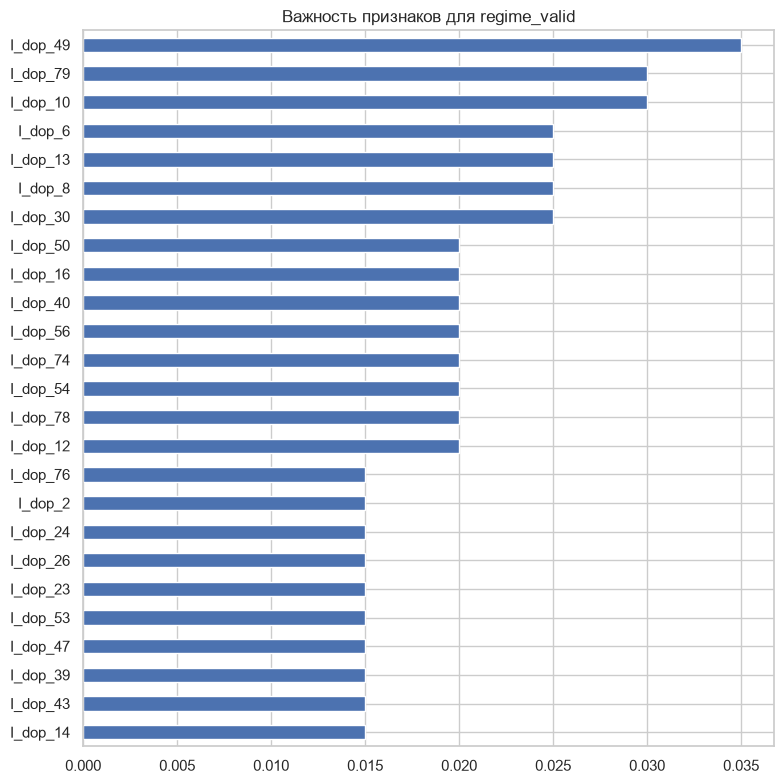

In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

Xtr, Xte, ytr, yte = train_test_split(f, y.loc[f.index], test_size=.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=200, max_depth=14, n_jobs=-1, random_state=42, class_weight="balanced")
rf.fit(Xtr, ytr)
pred = rf.predict(Xte)
print("F1-macro:", round(f1_score(yte, pred, average="macro"), 4))
print(classification_report(yte, pred))

fi = pd.Series(rf.feature_importances_, index=f.columns).sort_values(ascending=False)
fi.head(25).iloc[::-1].plot.barh(figsize=(8, 8), title="Важность признаков для regime_valid")
plt.tight_layout(); plt.show()

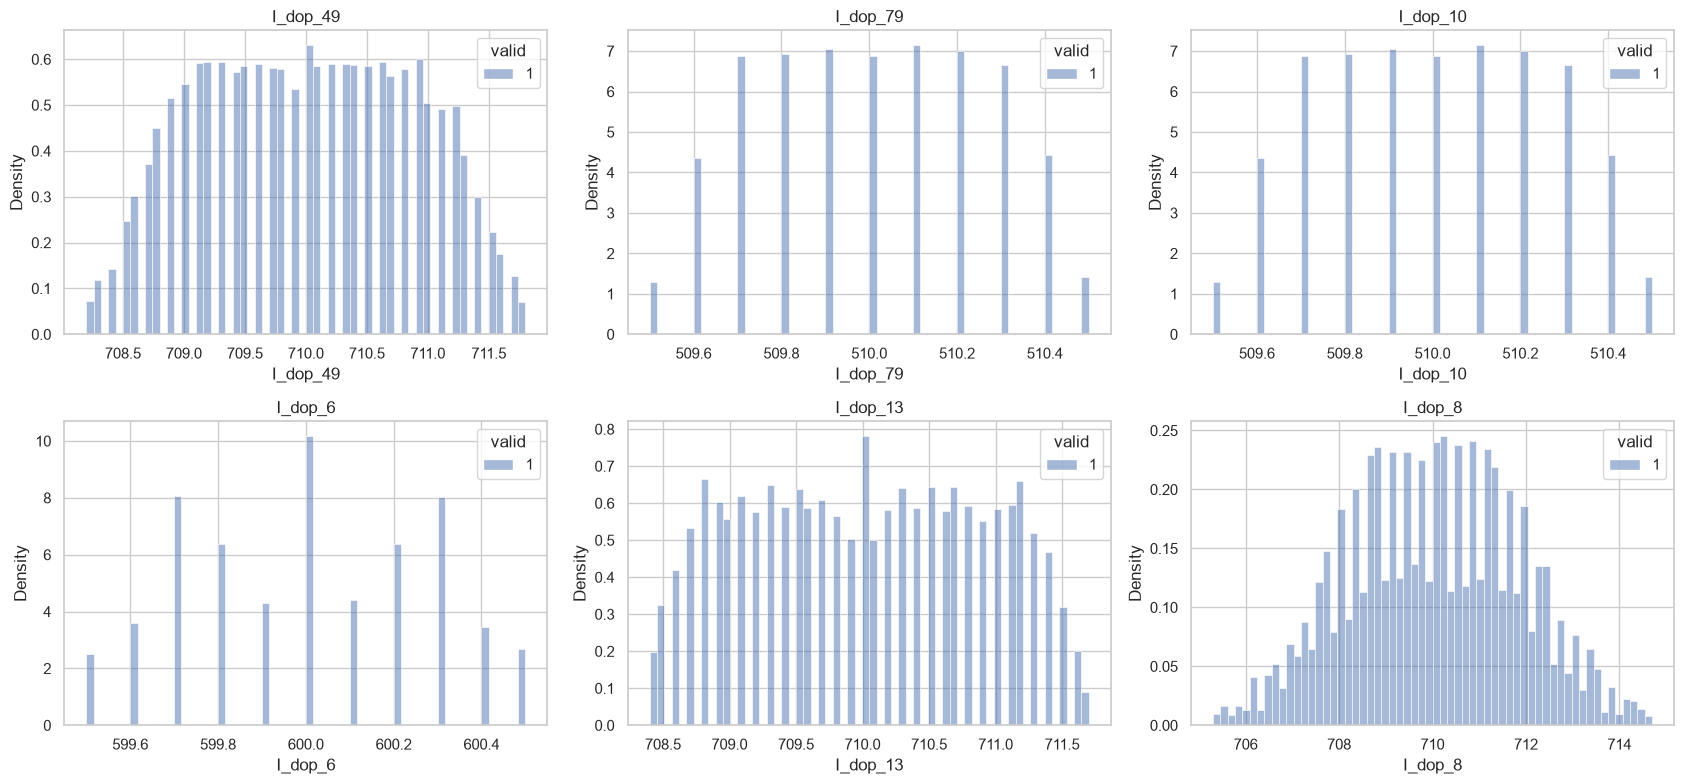

In [33]:
# Распределения главных агрегатов по флагу
top = fi.head(6).index.tolist()
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(ax.ravel(), top):
    d = pd.DataFrame({c: f[c], "valid": y.loc[f.index]})
    lo, hi = d[c].quantile([.005, .995])
    sns.histplot(data=d[d[c].between(lo, hi)], x=c, hue="valid", bins=60, stat="density", common_norm=False, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

## 7.2. Как вычисляется флаг `regime_valid`

Смотрим, какие ограничения и пороги стоят за флагом, и пробуем получить читаемое правило.

In [34]:
# (а) Интегральные показатели опыта по флагу: пределы по току, напряжению, углу
exp_stats = pd.DataFrame({
    "max_I_zarg": lines.groupby("id").I_zarg.max(),
    "n_lines_over100": lines.assign(o=lines.I_zarg > 100).groupby("id").o.sum(),
    "V_pu_min": nodes.groupby("id").V_pu.min(),
    "V_pu_max": nodes.groupby("id").V_pu.max(),
    "max_abs_Delta": nodes.assign(a=nodes.Delta.abs()).groupby("id").a.max(),
}).join(exp_valid)
display(exp_stats.groupby("valid_exp").describe().T)

valid_exp                       0           1
max_I_zarg      count      0.0000 50,085.0000
                mean          NaN    117.5321
                std           NaN     17.2884
                min           NaN     80.4000
                25%           NaN    104.4000
                50%           NaN    114.9000
                75%           NaN    128.5000
                max           NaN    185.4000
n_lines_over100 count 49,915.0000 50,085.0000
                mean       0.0000      3.3181
                std        0.0000      3.9189
                min        0.0000      0.0000
                25%        0.0000      1.0000
                50%        0.0000      1.0000
                75%        0.0000      4.0000
                max        0.0000     22.0000
V_pu_min        count 49,915.0000 50,085.0000
                mean       0.0000      0.7651
                std        0.0000      0.0678
                min        0.0000      0.5095
                25%        0.0000      0.7245
                50%        0.0000      0.7792
                75%        0.0000      0.8180
                max        0.0000      0.8836
V_pu_max        count 49,915.0000 50,085.0000
                mean       0.0000      1.0623
                std        0.0000      0.0001
                min        0.0000      1.0621
                25%        0.0000      1.0622
                50%        0.0000      1.0623
                75%        0.0000      1.0623
                max        0.0000      1.0624
max_abs_Delta   count 49,915.0000 50,085.0000
                mean       0.0000     40.0025
                std        0.0000      4.9009
                min        0.0000     29.7010
                25%        0.0000     36.2250
                50%        0.0000     39.2820
                75%        0.0000     43.1400
                max        0.0000     58.2530

In [35]:
# (б) Неглубокое дерево решений по входам -> читаемое правило для флага
from sklearn.tree import DecisionTreeClassifier, export_text

f2 = f.copy()
g_cols = [c for c in ["P_gen_29", "P_gen_33"] if c in f2]
f2["gen_29_33"] = f2[g_cols].sum(axis=1) if g_cols else 0.0
f2["deficit"] = f2["sum_P_load"] - f2["gen_29_33"]   # что должен покрыть балансировщик (+потери)
f2["deficit_share"] = f2["deficit"] / f2["sum_P_load"].replace(0, np.nan)
yy = y.loc[f2.index]

Xtr2, Xte2, ytr2, yte2 = train_test_split(f2.fillna(0), yy, test_size=.25, random_state=42, stratify=yy)
for depth in (2, 3, 4, 6):
    t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100, class_weight="balanced", random_state=42).fit(Xtr2, ytr2)
    print(f"depth={depth}: F1-macro = {f1_score(yte2, t.predict(Xte2), average='macro'):.4f}")

tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, class_weight="balanced", random_state=42).fit(f2.fillna(0), yy)
print(export_text(tree, feature_names=list(f2.columns), decimals=2))

depth=2: F1-macro = 1.0000
depth=3: F1-macro = 1.0000
depth=4: F1-macro = 1.0000
depth=6: F1-macro = 1.0000
|--- I_dop_22 <= 353.60
|   |--- class: 0
|--- I_dop_22 >  353.60
|   |--- I_dop_80 <= 509.55
|   |   |--- class: 1
|   |--- I_dop_80 >  509.55
|   |   |--- class: 1



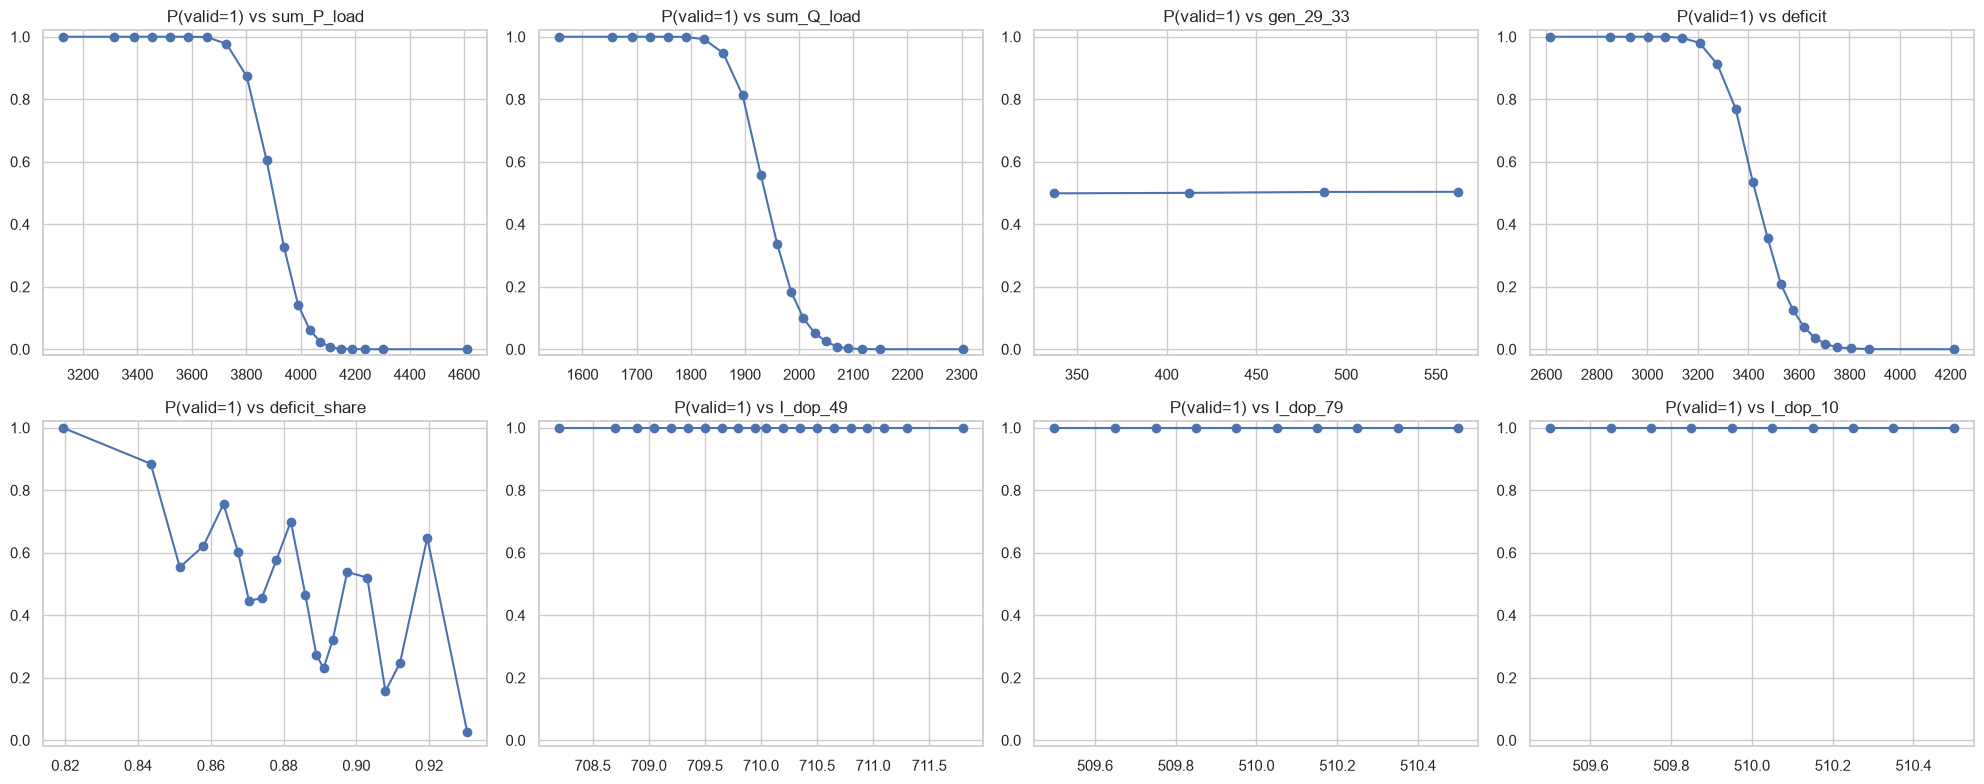

In [36]:
# (в) Доля валидных режимов по квантилям ключевых агрегатов - ищем пороги
cand = ["sum_P_load", "sum_Q_load", "gen_29_33", "deficit", "deficit_share"] + fi.head(3).index.tolist()
cand = list(dict.fromkeys([c for c in cand if c in f2]))
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for a, c in zip(axes, cand):
    b = pd.qcut(f2[c], 20, duplicates="drop")
    rate = yy.groupby(b, observed=True).mean()
    a.plot([iv.mid for iv in rate.index], rate.values, marker="o"); a.set_title(f"P(valid=1) vs {c}"); a.set_ylim(-.02, 1.02)
for a in axes[len(cand):]: a.axis("off")
plt.tight_layout(); plt.show()

## 8. Итоги (заполнить по результатам запуска)

* **Флаг:** гипотеза про единый флаг на опыт — см. раздел 1 (число смешанных опытов).
* **Q_н = k·P_н:** смотри `std(tg)` по узлам в разделе 2: ≈0 → константный коэффициент на узел.
* **P_г в 29/33:** раздел 3 (доля ненулевых, диапазон, связь между узлами).
* **Что на что влияет:** топ-пары в разделе 6; физическая проверка по линиям (6.2б).
* **Роли узлов:** раздел 3.1 (29/33 - генераторы, -1 (999) - балансировщик, остальные - потребители/транзит).
* **Эталонный узел -1 (999):** раздел 6.3 (его V/Delta, токи линий к нему, связь с небалансом генерация − нагрузка).
* **Как считается флаг:** раздел 7.2 (пределы по I/V/Delta, дерево решений, пороги по дефициту генерации).
* **Сходимость:** разница входов и важность признаков (раздел 7) — основа для фичей классификатора.